In [17]:
## 1. Imports and settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pygam import LinearGAM, s, f, l
import enigmatoolbox.datasets as enigma_datasets

DATA_DIR = Path('/data/pt_03279/epilepsy_project/Epilepsy')
COHORT = 'GGE'
TEST_SIZE = .20
SEED = 42
ROI = 'L_entorhinal'
CURVE_SEX = 2
AGE_BINS = [18, 30, 45, 66]
AGE_LABELS = ['18-29', '30-44', '45-65']
RUN_TAG = f'AgeSexICV_PI95_HC{round(100 * (1 - TEST_SIZE))}_seed{SEED}'
OUT_ROOT = Path('GAM_results_v2')
OUT_DIR = OUT_ROOT / COHORT / RUN_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert 0 < TEST_SIZE < 1 and CURVE_SEX in [1, 2]
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()


In [18]:
## 2. Load data and split healthy controls
demo = pd.read_csv(DATA_DIR / 'demo.csv', index_col=0)
tle = pd.read_csv(DATA_DIR / 'ctx_tle.csv', index_col=0).astype(float)
gge = pd.read_csv(DATA_DIR / 'ctx_ige.csv', index_col=0).astype(float)

assert demo.index.is_unique and tle.index.is_unique and gge.index.is_unique
assert tle.columns.is_unique and gge.columns.is_unique
assert set(tle.columns) == set(gge.columns)

controls = tle.loc[pd.to_numeric(demo.loc[tle.index, 'Dx']).eq(0)]
patients = gge.loc[pd.to_numeric(demo.loc[gge.index, 'Dx']).eq(1), tle.columns]
ctx = pd.concat([controls, patients])
assert ctx.shape[1] == 68 and np.isfinite(ctx.to_numpy()).all()
dem = demo.loc[ctx.index].copy()
dem[['Age', 'Sex', 'ICV', 'Dx', 'SDx']] = dem[
    ['Age', 'Sex', 'ICV', 'Dx', 'SDx']].apply(pd.to_numeric, errors='raise')
X = dem[['Age', 'Sex', 'ICV']].to_numpy(dtype=float)
hc = dem.Dx.eq(0)
rng = np.random.default_rng(SEED)
train_ids, test_ids = [], []
for _, group in dem.loc[hc].groupby('Site', sort=True):
    ids = rng.permutation(group.index.to_numpy())
    n = 0 if len(ids) == 1 else int(np.ceil(TEST_SIZE * len(ids)))
    test_ids.extend(ids[:n])
    train_ids.extend(ids[n:])
train, test = dem.index.isin(train_ids), dem.index.isin(test_ids)
assert train.any() and test.sum() >= 2 and set(dem.loc[train, 'Sex']) == {1, 2}
analysis_ids = dem.index[~train]
split_info = dem[['Age', 'Sex', 'ICV', 'Dx', 'SDx', 'Site']].copy()
split_info['Role'] = np.select([train, test], ['HC_train', 'HC_test'], default='patient')
split_info['Age_extrapolated'] = ~dem.Age.between(*dem.loc[train, 'Age'].agg(['min', 'max']))
print(split_info.Role.value_counts())


Role
HC_train    561
patient     215
HC_test     144
Name: count, dtype: int64


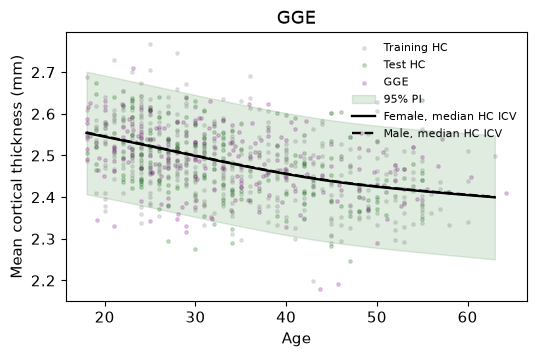

In [19]:
## 3. Mean cortical thickness: GAM demonstration
mean_ct = ctx.mean(axis=1)
mean_gam = LinearGAM(s(0) + f(1) + l(2)).gridsearch(
    X[train], mean_ct.loc[train].to_numpy(), progress=False)
assert mean_gam.logs_['diffs'][-1] < mean_gam.tol, 'Mean CT GAM did not converge.'
age = np.linspace(dem.loc[train, 'Age'].min(), dem.loc[train, 'Age'].max(), 200)
grid = np.column_stack([age, np.full(len(age), CURVE_SEX),
                       np.full(len(age), dem.loc[train, 'ICV'].median())])

def gam_plot(model, observed, ylabel, name):
    fig, ax = plt.subplots(figsize=(5.5, 3.7))
    for role, label, color in [('HC_train', 'Training HC', 'grey'),
            ('HC_test', 'Test HC', 'darkgreen'), ('patient', COHORT, 'purple')]:
        ids = split_info.index[split_info.Role.eq(role)]
        ax.scatter(dem.loc[ids, 'Age'], observed.loc[ids],
            s=6, alpha=.2, color=color, label=label)
    pi = model.prediction_intervals(grid, width=.95)
    ax.fill_between(age, pi[:, 0], pi[:, 1], color='darkgreen', alpha=.12, label='95% PI')
    ax.plot(age, model.predict(grid), color='black', lw=1.7,
        label=f'{["Male", "Female"][CURVE_SEX - 1]}, median HC ICV')
    grid_male = grid.copy()
    grid_male[:, 1] = 1
    ax.plot(age, model.predict(grid_male), color='black', ls='--', lw=1.7,
        label='Male, median HC ICV')
    ax.set(xlabel='Age', ylabel=ylabel, title=COHORT)
    ax.legend(frameon=False, fontsize=8)
    save(fig, name)

gam_plot(mean_gam, mean_ct, 'Mean cortical thickness (mm)', '01_Mean_CT_GAM')
mean_pi = mean_gam.prediction_intervals(X, width=.95)
mean_ct_results = pd.DataFrame({'Observed': mean_ct, 'Predicted': mean_gam.predict(X),
    'PI_low': mean_pi[:, 0], 'PI_high': mean_pi[:, 1]})


In [20]:
## 4. Regional GAMs, deviation scores 
models, predicted, pi_width = {}, ctx.copy(), ctx.copy()
for region in ctx:
    gam = LinearGAM(s(0) + f(1) + l(2)).gridsearch(
        X[train], ctx.loc[train, region].to_numpy(), progress=False)
    assert gam.logs_['diffs'][-1] < gam.tol, f'No convergence: {region}'
    models[region] = gam
    predicted[region] = gam.predict(X)
    pi = gam.prediction_intervals(X, width=.95)
    pi_width[region] = pi[:, 1] - pi[:, 0]
ctx_resid = ctx - predicted
assert pi_width.gt(0).all().all()
ctx_z = 4 * ctx_resid / pi_width
assert np.isfinite(ctx_z.to_numpy()).all()

In [21]:
## 5. Psychiatric reference maps and individual RVI
map_specs = {'ADHD': ('adhd', 'CortThick_case_vs_controls_adult'),
    'ASD': ('asd', 'CortThick_case_vs_controls_meta_analysis'),
    'BD': ('bipolar', 'CortThick_case_vs_controls_adult'),
    'MDD': ('depression', 'CortThick_case_vs_controls_adult'),
    'OCD': ('ocd', 'CortThick_case_vs_controls_adult'),
    'SCZ': ('schizophrenia', 'CortThick_case_vs_controls')}
enigma_dir = Path(enigma_datasets.__file__).parent / 'summary_statistics'
ct_maps = {}
for name, (disorder, table_name) in map_specs.items():
    table = (pd.read_csv(enigma_dir / 'scz_case-controls_CortThick.csv') if name == 'SCZ'
             else enigma_datasets.load_summary_stats(disorder)[table_name])
    ct_maps[name] = pd.Series(table.d_icv.to_numpy(dtype=float), index=table.Structure)
CT_d = pd.concat(ct_maps, axis=1)
assert CT_d.index.is_unique and set(CT_d.index) == set(ctx_z.columns)
CT_d = CT_d.loc[ctx_z.columns]
assert np.isfinite(CT_d.to_numpy()).all()
RVI = pd.DataFrame({name: ctx_z.T.corrwith(CT_d[name]) for name in CT_d}, index=ctx_z.index)
assert np.isfinite(RVI.to_numpy()).all()
order = list(RVI.columns)
analysis_demo = dem.loc[analysis_ids].copy()
analysis_demo['Sex_binary'] = analysis_demo.Sex.eq(1).astype(int)
analysis_demo['Dx_x_Sex'] = analysis_demo.Dx * analysis_demo.Sex_binary
terms = ['Dx', 'Sex_binary', 'Dx_x_Sex']
rvi_data = RVI.loc[analysis_ids].join(analysis_demo)


,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.029185,-0.075606,0.017236,-1.236423,0.217114
1,ASD,0.010208,-0.034371,0.054786,0.450318,0.652755
2,BD,0.025327,-0.017266,0.067919,1.169412,0.243018
3,MDD,-0.061800,-0.111133,-0.012467,-2.463624,0.014225
4,OCD,0.048708,0.013730,0.083686,2.738587,0.006480
5,SCZ,-0.016558,-0.057383,0.024267,-0.797641,0.425609


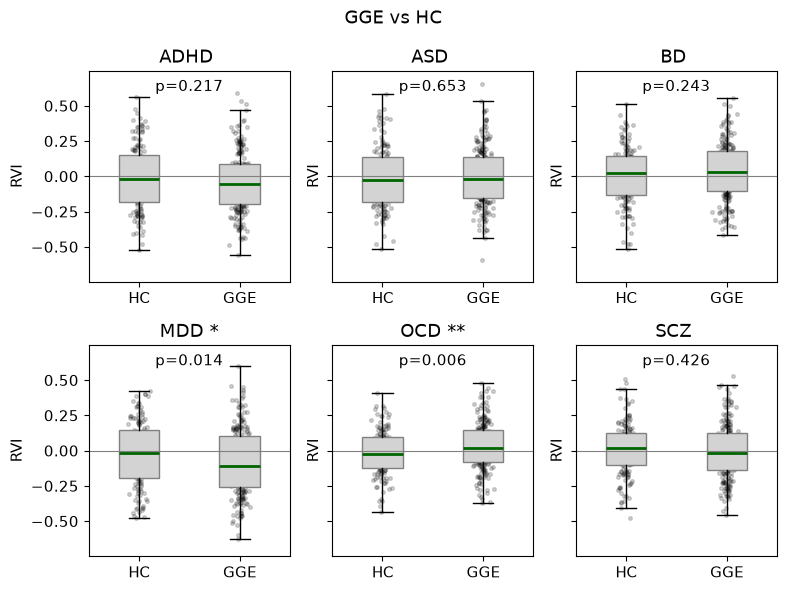

In [22]:
## 6. RVI: case-control differences and boxplots
def effect_table(outcomes, covariates, term):
    design = sm.add_constant(covariates.astype(float), has_constant='add')
    assert outcomes.index.equals(design.index)
    rows = []
    for name in outcomes:
        fit = sm.OLS(outcomes[name], design, missing='raise').fit()
        low, high = fit.conf_int().loc[term]
        rows.append([name, fit.params[term], low, high, fit.tvalues[term], fit.pvalues[term]])
    return pd.DataFrame(rows, columns=['Outcome', 'Beta', 'CI_low', 'CI_high', 'T', 'P'])

case_control_results = effect_table(rvi_data[order], rvi_data[['Dx']], 'Dx').rename(
    columns={'Outcome': 'Disorder'})
display(case_control_results)
star = lambda p: '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''
pfmt = lambda p: 'p<.001' if p < .001 else f'p={p:.3f}'
fig, axes = plt.subplots(2, 3, figsize=(8, 6), sharey=True)
plot_rng = np.random.default_rng(SEED)
rvi_limit = min(1.12, max(.7, np.abs(rvi_data[order].to_numpy()).max() * 1.14))
for ax, disorder in zip(axes.flat, order):
    values = [rvi_data.loc[rvi_data.Dx.eq(dx), disorder] for dx in [0, 1]]
    p = case_control_results.set_index('Disorder').loc[disorder, 'P']
    bp = ax.boxplot(values, widths=.4, showfliers=False, patch_artist=True,
        medianprops={'color': 'darkgreen', 'linewidth': 2})
    for box in bp['boxes']:
        box.set(facecolor='lightgrey', edgecolor='grey')
    for x, y in enumerate(values, 1):
        ax.scatter(plot_rng.normal(x, .04, len(y)), y, s=7, alpha=.17, color='black')
    ax.axhline(0, color='grey', lw=.8)
    ax.set(xticks=[1, 2], xticklabels=['HC', COHORT], ylim=(-rvi_limit, rvi_limit),
        title=f'{disorder} {star(p)}', ylabel='RVI')
    ax.text(.5, .96, pfmt(p), transform=ax.transAxes, ha='center', va='top')
fig.suptitle(f'{COHORT} vs HC')
save(fig, f'{COHORT}_vs_HC')


,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.068717,-0.163023,0.025590,-1.433014,0.152734
1,ASD,-0.003453,-0.094235,0.087328,-0.074809,0.940409
2,BD,-0.082421,-0.168349,0.003508,-1.886384,0.060059
3,MDD,-0.123724,-0.222781,-0.024668,-2.456427,0.014511
4,OCD,-0.066749,-0.135655,0.002157,-1.905100,0.057575
5,SCZ,-0.077580,-0.159951,0.004792,-1.852266,0.064818


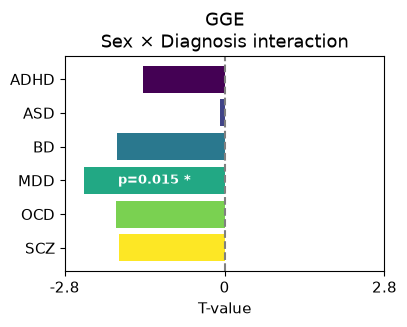

In [23]:
## 7. RVI: Sex × Dx interaction
interaction_results = effect_table(rvi_data[order], rvi_data[terms], 'Dx_x_Sex').rename(
    columns={'Outcome': 'Disorder'})
display(interaction_results)

def interaction_plot(results, title, ax, limit=None):
    d = results.set_index('Disorder').loc[order]
    if limit is None:
        limit = max(.5, np.ceil(d['T'].abs().max() * 1.12 * 10) / 10)
    bars = ax.barh(d.index, d['T'], color=plt.cm.viridis(np.linspace(0, 1, len(order))))
    ax.axvline(0, color='grey', ls='--')
    ax.set(xlim=(-limit, limit), xticks=[-limit, 0, limit],
        xticklabels=[f'{-limit:g}', '0', f'{limit:g}'], xlabel='T-value', title=title)
    for bar, p in zip(bars, d.P):
        if p < .05:
            ax.text(bar.get_width() / 2, bar.get_y() + bar.get_height() / 2,
                f'{pfmt(p)} {star(p)}', ha='center', va='center', fontsize=9,
                color='white' if bar.get_facecolor()[0] < .5 else 'black', fontweight='bold')
    ax.invert_yaxis()

fig, ax = plt.subplots(figsize=(4.2, 3.4))
interaction_plot(interaction_results, f'{COHORT}\nSex × Diagnosis interaction', ax)
save(fig, f'{COHORT}_Sex_Dx')


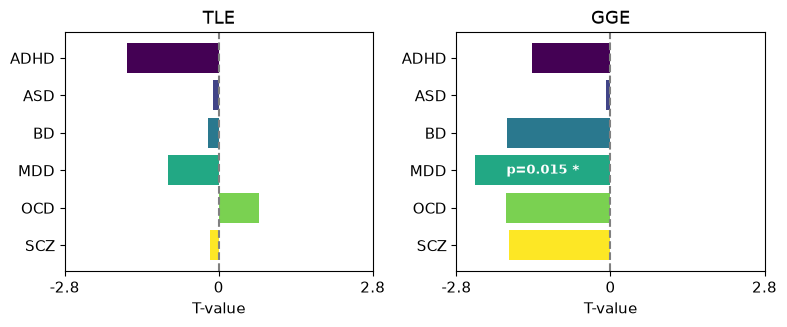

In [24]:
## 8. Save results and paired TLE-GGE interaction plot
tables = {
    'mean_CT_demo': mean_ct_results,
    'ctx_predicted': predicted,
    'PI95_width': pi_width,
    'ctx_z_all': ctx_z,
    'RVI_all': RVI,
    'RVI_analysis': rvi_data,
    'split_info': split_info,
    'reference_maps': CT_d,
    'case_control_results': case_control_results,
    'interaction_results': interaction_results
}
for name, table in tables.items():
    table.to_csv(OUT_DIR / f'{name}.csv')
paths = {name: OUT_ROOT / name / RUN_TAG / 'interaction_results.csv' for name in ['TLE', 'GGE']}
if all(path.exists() for path in paths.values()):
    paired = {name: pd.read_csv(path, index_col=0) for name, path in paths.items()}
    limit = max(.5, np.ceil(max(d['T'].abs().max() for d in paired.values()) * 1.12 * 10) / 10)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
    for ax, (name, result) in zip(axes, paired.items()):
        interaction_plot(result, name, ax, limit)
    save(fig, 'TLE_GGE_Sex_Dx')

